<a href="https://colab.research.google.com/github/CSE-Mashal/svd-image-compression/blob/main/notebooks/02%20svd%20approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


A is a 512 x 512 matrix. I changed it to float so the pixel values do not wrap around during calculations.

In [2]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)
A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


SVD splits the matrix into U, singular values, and Vt. Multiplying them back together gives the original image. The tiny error comes from rounding in the calculations.

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


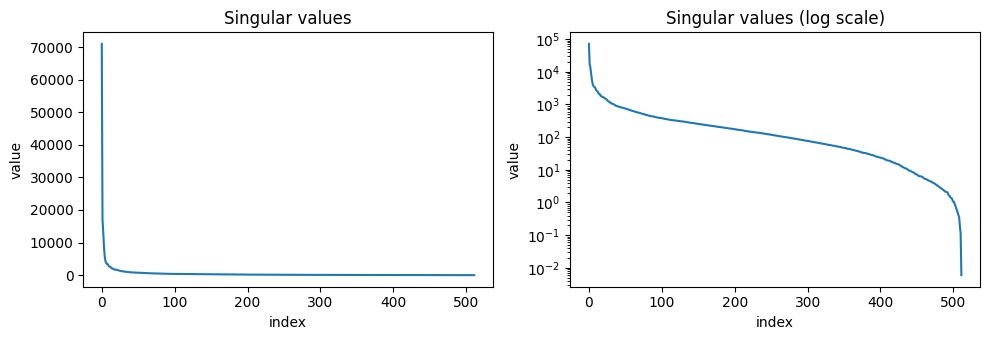

In [3]:
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1), round(s[199], 1), round(s[-1], 3))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)", xlabel="index", ylabel="value")
plt.tight_layout()
plt.show()

The singular values get smaller as you go down the list. The first ones contribute the most to the image. The log graph helps show the smaller values more clearly.

In [4]:
def rank_k_approx(A, k):
    """Return the rank-k SVD approximation of A."""
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:", np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


Using the first k singular values makes a rank-k image. With k = 10 the rank is 10, and with k = 512 I get the original image back. The stripes only have one nonzero singular value.

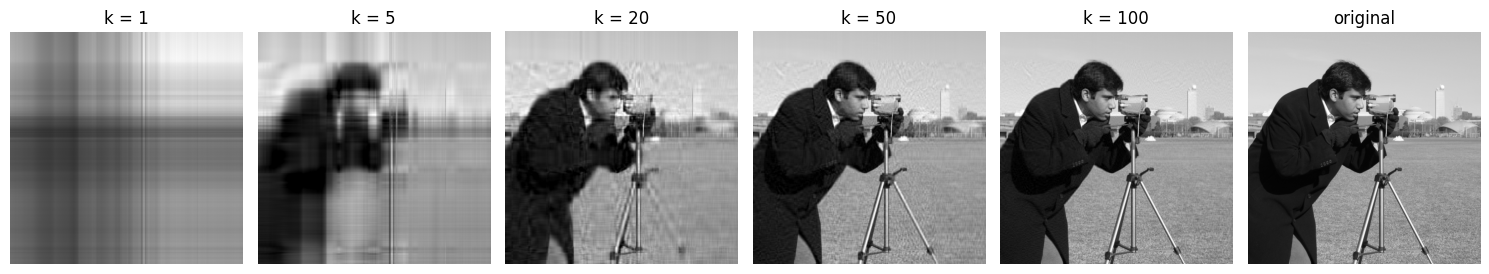

In [5]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
    Ak = np.clip(rank_k_approx(A, k), 0, 255)
    ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")
axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

When k is smaller, the image is more blurry. As k gets bigger, I can see more of the details.

## Exercises

In [6]:
M = np.array([[3, 0], [4, 5]])
print("M.T @ M:", M.T @ M)
print("Eigenvalues:", np.linalg.eigvalsh(M.T @ M))
print("Singular values:", np.linalg.svd(M, compute_uv=False))

M.T @ M: [[25 20]
 [20 25]]
Eigenvalues: [ 5. 45.]
Singular values: [6.70820393 2.23606798]


M.T @ M = [[25, 20], [20, 25]]. The eigenvalues are 45 and 5, so the singular values are sqrt(45) = 6.708 and sqrt(5) = 2.236. The Python results match. If both u1 and v1 change signs, the negatives cancel and their outer product stays the same.

In [7]:
error1 = np.linalg.norm(A - rank_k_approx(A, 20))
error2 = np.sqrt(np.sum(s[20:]**2))
print("Error from matrices:", error1)
print("Error from singular values:", error2)
print("Do they agree?", np.allclose(error1, error2))

Error from matrices: 7699.9091419681245
Error from singular values: 7699.9091419681245
Do they agree? True


Both errors are almost the same. The slice starts at s[20:] because the first 20 singular values are used, so index 20 is the first one left out.

Saving photolinear.png to photolinear (1).png


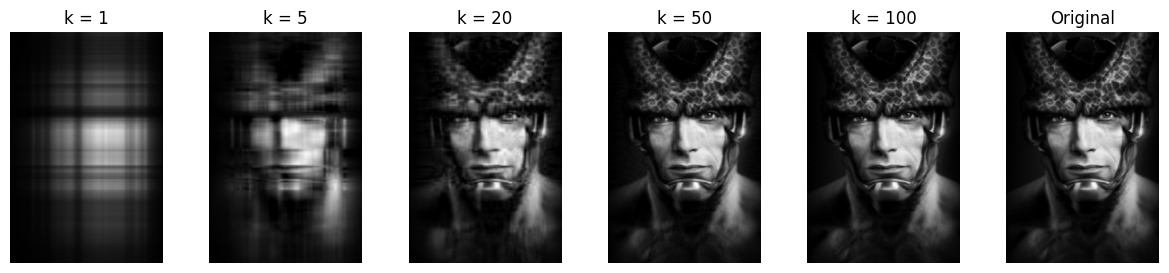

In [8]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
name = list(uploaded)[0]
img = Image.open(name).convert("L")
img.thumbnail((800, 800))
P = np.array(img).astype(float)

ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
    Pk = np.clip(rank_k_approx(P, k), 0, 255)
    ax.imshow(Pk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")
axes[-1].imshow(P, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("Original")
axes[-1].axis("off")
plt.show()

The smallest k where I can recognize my picture is k=20. My picture has more dark areas and different details than the camera image, so it may need a different k to be recognizable.